[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_mad/BA_L1_mad.ipynb)

# BA_L1_mad: The Outlier Rule on the Data

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

A robust z-score based on the median and the median absolute deviation (MAD) on a centred 31-day window, applied to the raw daily log market value of Bitcoin, November 2014 to 8 October 2025; the threshold 10 flags the 11 days of recording error.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

The mean and the standard deviation are themselves distorted by outliers. A robust z-score uses the median and the
**median absolute deviation** (MAD) on a 31-day window $W_t$ centred on day $t$:

$$z_t = \frac{x_t - \mathrm{med}_t}{1.4826\,\mathrm{MAD}_t}, \qquad \mathrm{MAD}_t = \mathrm{med}_{s \in W_t}\,\big|x_s - \mathrm{med}_t\big|,$$

where $\mathrm{med}_t$ is the median of $x_s$ over $W_t$ and $x_t$ the log market value of Bitcoin (raw series, with
the 11 bad days of 27 August to 6 September 2023). The factor 1.4826 makes $1.4826\,\mathrm{MAD}$ equal to the
standard deviation for Normal data. Days with $\mathrm{MAD}_t = 0$ have no finite $z_t$ and are left out.

**How to read the chart.** Left: the raw market value with the days flagged by $|z_t| > 10$. Right: $|z_t|$ on a log
scale with the threshold 10 and the usual threshold 3.

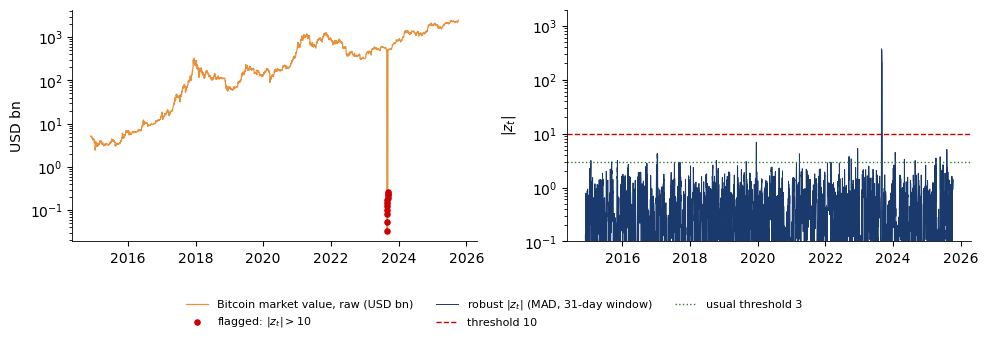

In [5]:
raw_btc = load_onchain('Mktcap')['BTC']
lx = np.log(raw_btc)
med = lx.rolling(31, center=True, min_periods=15).median()


def window_mad(a):
    # median absolute deviation from the median of the same window
    a = a[~np.isnan(a)]
    return np.median(np.abs(a - np.median(a)))


mad = lx.rolling(31, center=True, min_periods=15).apply(window_mad, raw=True)
z = (lx - med) / (1.4826 * mad)
n_mad0 = int((mad == 0).sum())
z = z[np.isfinite(z)]
THR = 10
flag = z.abs() > THR

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(raw_btc.index, raw_btc / 1e9, color=BTC, lw=0.9, label='Bitcoin market value, raw (USD bn)')
fl = flag[flag].index
ax[0].scatter(fl, raw_btc[fl] / 1e9, color=RED, s=14, zorder=5, label=r'flagged: $|z_t| > 10$')
ax[0].set_yscale('log'); ax[0].set_ylabel('USD bn')
ax[1].plot(z.index, z.abs().clip(lower=0.1), color=BLUE, lw=0.7, label=r'robust $|z_t|$ (MAD, 31-day window)')
ax[1].axhline(THR, color=RED, ls='--', lw=1, label='threshold 10')
ax[1].axhline(3, color=GREEN, ls=':', lw=1, label='usual threshold 3')
ax[1].set_yscale('log'); ax[1].set_ylim(0.1, 2000); ax[1].set_ylabel(r'$|z_t|$')
slide_legend(fig, 0.16)
save_fig(fig, 'ba_l1_mad')

In [6]:
bad_days = z.loc['2023-08-27':'2023-09-06'].abs()
other = z.drop(bad_days.index).abs()
big3 = z.abs() > 3
print(f'Days with a finite robust z-score: {len(z):,}; days with MAD = 0 (left out): {n_mad0}')
print(f'The {len(bad_days)} bad days: |z| between {bad_days.min():.1f} and {bad_days.max():.1f}')
print(f'Largest |z| on any other day: {other.max():.1f} ({other.idxmax():%d %B %Y})')
print(f'Days flagged by |z| > {THR}: {int(flag.sum())}; by the usual |z| > 3: {int(big3.sum())}, '
      f'of which genuine moves (not the bad days): {int(big3.drop(bad_days.index).sum())}')

Days with a finite robust z-score: 3,968; days with MAD = 0 (left out): 0
The 11 bad days: |z| between 57.0 and 373.1
Largest |z| on any other day: 6.9 (17 December 2019)
Days flagged by |z| > 10: 11; by the usual |z| > 3: 46, of which genuine moves (not the bad days): 35
